# Warps in Edge-on-Galaxien

Das Notebook lädt Bilder von Scheibengalaxien in Kantenlage aus den DESI Legacy Imaging Surveys (DECaLS, r-Band), bestimmt in jeder Bildspalte mit einem Gauß-Fit die Höhe der hellsten Stelle der Scheibe (die „Spine“) und misst, wie weit die äußere Spine von der Ebene der inneren Scheibe abweicht. Es ordnet die Form ein (S, U oder einseitig), prüft mit dem g- und z-Band, ob Staub die Messung verfälscht, und vergleicht Form und Warp-Winkel mit dem Katalog von Sánchez-Saavedra et al. (2003).

Ist die Sternscheibe von ESO 240-011 außen verbogen, und wenn ja, wie stark und in welcher Form?

(DECaLS-Bilder, Spine-Fit, Warp-Profil und Warp-Winkel, Staubtest in g, r und z, Vergleich mit dem Warp-Katalog (ESO 240-011))

#### **Hintergrund**

Die Scheibe einer Spiralgalaxie ist innen meist eben, außen aber oft verbogen. Zuerst sah man das im neutralen Wasserstoff (HI), der weiter hinausreicht als die Sterne: Sancisi (1976) fand bei vier von fünf Galaxien in Kantenlage, dass die HI-Scheibe außen aus der Ebene herausbiegt, am deutlichsten bei NGC 5907. García-Ruiz et al. (2002) fanden in 20 von 26 Galaxien einen HI-Warp, und zwar in allen, deren HI-Scheibe über die Sternscheibe hinausreicht; der Warp beginnt meist dort, wo die Sternscheibe endet. In den Sternen ist der Effekt kleiner, aber in optischen Bildern oft noch messbar: Reshetnikov & Combes (1998) fanden in etwa 40 % von 540 Galaxien in Kantenlage einen S-förmigen Warp. Auch die Milchstraße ist verbogen; Cepheiden zeigen, dass ihre Sternscheibe außerhalb der Sonnenbahn auf der einen Seite nach oben, auf der anderen nach unten abbiegt (Chen et al. 2019).

Als Ursachen werden diskutiert:
- ein Halo aus Dunkler Materie, dessen Achse gegen die Scheibe gekippt ist; die äußere Scheibe stellt sich dann auf den Halo ein (Sparke & Casertano 1988),
- Material, das mit einem anders ausgerichteten Drehimpuls einfällt (Ostriker & Binney 1989; Jiang & Binney 1999),
- Gezeitenkräfte von Begleitern, bei der Milchstraße etwa der Magellanschen Wolken (Weinberg & Blitz 2006).

In der Projektion unterscheidet man drei Formen:
- **S-Warp**: eine Seite biegt nach oben, die andere nach unten (punktsymmetrisch, der häufigste Fall)
- **U-Warp**: beide Seiten biegen in dieselbe Richtung
- **L-Warp**: nur eine Seite ist verbogen

Messen lässt sich das nur bei fast exakter Kantenlage ($i \gtrsim 85^\circ$). Bei kleinerer Neigung verschmiert die Projektion den Warp, und Spiralarme können einen vortäuschen. Projekte wie die MUSE-Durchmusterung GECKOS (van de Sande et al. 2024) wählen deshalb Galaxien in Kantenlage aus.

Die Methode hier: Man verfolgt die hellste Stelle jeder Bildspalte, die Spine, und vergleicht ihren äußeren Teil mit der Ebene der inneren Scheibe. Der Abstand in kpc ist die Warp-Amplitude, der Winkel vom Zentrum aus gesehen der Warp-Winkel.

#### **Herleitung**

**1. Lage der Scheibe.** Die Helligkeit $f$ der Pixel wird wie eine Massenverteilung behandelt. Ihr Schwerpunkt ist $\bar x = \sum f x / \sum f$ (und $\bar y$ entsprechend), die zweiten Momente sind
$$\mu_{xx} = \frac{\sum f\,(x-\bar x)^2}{\sum f}, \qquad \mu_{yy} = \frac{\sum f\,(y-\bar y)^2}{\sum f}, \qquad \mu_{xy} = \frac{\sum f\,(x-\bar x)(y-\bar y)}{\sum f} .$$
Dreht man die Achsen um den Winkel $\theta$, also $x' = x\cos\theta + y\sin\theta$ und $y' = -x\sin\theta + y\cos\theta$, dann ist $x'y' = (y^2 - x^2)\sin\theta\cos\theta + xy\,(\cos^2\theta - \sin^2\theta)$ und damit
$$\mu_{x'y'} = \tfrac12(\mu_{yy}-\mu_{xx})\sin 2\theta + \mu_{xy}\cos 2\theta .$$
Entlang der Hauptachsen der Verteilung verschwindet dieses gemischte Moment. Aus $\mu_{x'y'} = 0$ folgt
$$\tan 2\theta = \frac{2\mu_{xy}}{\mu_{xx}-\mu_{yy}} .$$
Die Gleichung hat zwei Lösungen im Abstand von 90°, die große und die kleine Achse. Die Form $\theta = \tfrac12\,\mathrm{atan2}(2\mu_{xy},\, \mu_{xx}-\mu_{yy})$ wählt die große: Mit ihr ist $\mu_{x'x'} = \tfrac12(\mu_{xx}+\mu_{yy}) + \tfrac12\sqrt{(\mu_{xx}-\mu_{yy})^2 + 4\mu_{xy}^2}$, der größere der beiden Werte. Das Bild wird um $\theta$ gedreht, bis die Scheibe waagerecht liegt, und zwar so, dass das Ostende links liegt wie am Himmel. Über die Himmelskoordinaten des Bildes (WCS) wird $\theta$ in den Positionswinkel PA umgerechnet, gezählt von Norden über Osten.

**2. Spine.** Für jeden Radius $R$ (eine Gruppe von $N$ = `BIN` Spalten des gedrehten Bildes) wird an das senkrechte Helligkeitsprofil eine Gaußkurve angepasst:
$$I(z) = A\,\exp\!\left(-\frac{(z-z_0)^2}{2\sigma^2}\right) + c .$$
Die Spine ist $z_0(R)$. Das wahre senkrechte Profil einer Scheibe ist eher $\mathrm{sech}^2(z/z_s)$ (van der Kruit & Searle 1981). Für die Lage des Maximums spielt das keine Rolle, weil beide Kurven symmetrisch um ihr Maximum sind. Mittelt man $N$ Spalten mit unabhängigem Rauschen $\sigma_\mathrm{bg}$ pro Pixel, addieren sich die Varianzen: $\mathrm{Var}\big(\tfrac1N\sum_i n_i\big) = \tfrac{1}{N^2}\cdot N\sigma_\mathrm{bg}^2$. Das Rauschen sinkt also auf $\sigma_\mathrm{bg}/\sqrt N$, und das Signal-Rausch-Verhältnis einer Spalte ist
$$\mathrm{SNR} = \frac{A}{\sigma_\mathrm{bg}/\sqrt{N}} .$$
Behalten werden Spalten mit $\mathrm{SNR} > 5$. Sterne fallen heraus, weil ihr Profil schmaler ist als das der Scheibe ($\sigma < 0.6\,\sigma_\mathrm{Scheibe}$). Weil der Cutout-Dienst die Bilder neu abtastet und die Drehung interpoliert, ist das Rauschen benachbarter Pixel etwas korreliert; das SNR ist deshalb eine Näherung.

**3. Referenzebene.** Angenommen wird, dass die innere Scheibe ($|R| < 0.3\,R_\mathrm{max}$, `R_INNER`) eben ist. Dort wird eine Gerade $z = aR + b$ angepasst. Sie fängt eine kleine Restverdrehung ($a$) und einen Versatz ($b$) des Bildes auf.

**4. Warp-Profil.** Gesucht ist der senkrechte Abstand eines Spine-Punkts $P = (R, z)$ von dieser Geraden. Die Gerade geht durch $P_0 = (0, b)$ und hat die Richtung $(1, a)$. Ein Vektor senkrecht dazu mit Länge 1 ist $\hat n = (-a, 1)/\sqrt{1+a^2}$, denn $(1, a)\cdot(-a, 1) = 0$. Der Abstand ist die Projektion von $P - P_0 = (R,\, z - b)$ auf $\hat n$:
$$z_\mathrm{warp}(R) = (P - P_0)\cdot\hat n = \frac{-aR + z - b}{\sqrt{1+a^2}} = \frac{z - (aR+b)}{\sqrt{1+a^2}} .$$
Das Vorzeichen bleibt erhalten: positiv über der Ebene, negativ darunter.

**5. Von Pixeln zu kpc.** Ein kleiner Winkel $\alpha$ (im Bogenmaß) bei der Entfernung $D$ entspricht der Länge $\ell = D\,\alpha$. Eine Bogensekunde ist $\pi/(180\cdot 3600) = 4.848\cdot 10^{-6}$ rad, also entspricht $1''$ der Länge $4.848\,\mathrm{pc}\cdot D/\mathrm{Mpc}$. Die Entfernung kommt aus SIMBAD: der Median aller veröffentlichten Messungen, die nicht auf der Rotverschiebung beruhen (meist Tully-Fisher). Nur wenn es keine gibt, wird $D = cz/H_0$ genommen. Bei nahen Galaxien ist das ungenau, weil die Eigenbewegung von einigen hundert km/s dort vergleichbar mit $cz$ selbst ist (NGC 5907: $cz \approx 670$ km/s, also $cz/H_0 = 9.5$ Mpc gegen 15.8 Mpc aus Tully-Fisher).

**6. Amplitude und Warp-Winkel.** Für jede Seite ist die Warp-Amplitude der Median von $z_\mathrm{warp}$ im äußersten Viertel der messbaren Spine; sie ist also kleiner als die größte Auslenkung am Rand. Der Warp-Winkel ist der Winkel zwischen äußerer Scheibe und innerer Ebene, vom Zentrum aus gesehen:
$$\psi = \arctan\frac{z_\mathrm{warp}}{|R|} ,$$
mit den Medianen von $z_\mathrm{warp}$ und $|R|$ im selben Viertel. Sánchez-Saavedra et al. (2003) definieren ihren Winkel genauso, nehmen aber den äußersten sichtbaren Punkt und zählen eine Scheibe erst ab $\psi > 4^\circ$ als verbogen.

**7. Form.** Jedes Paar von Amplituden $(z_O, z_W)$ für Ost- und Westseite lässt sich eindeutig in einen punktsymmetrischen Teil $S$ und einen spiegelsymmetrischen Teil $U$ zerlegen:
$$z_O = U - S, \quad z_W = U + S \quad\Rightarrow\quad S = \tfrac12(z_W - z_O), \quad U = \tfrac12(z_W + z_O) .$$
Ein reiner S-Warp hat $U = 0$, ein reiner U-Warp $S = 0$, ein einseitiger $|S| = |U|$. Für die Einordnung wird jede Seite mit der Streuung $s$ der inneren Punkte verglichen. Für normalverteiltes Rauschen ist der Median der Absolutabweichungen (MAD) gleich $0.6745\,\sigma$; also ist $s = 1.4826\cdot\mathrm{MAD}$ ein Schätzer für $\sigma$, der Ausreißer kaum spürt. Als Untergrenze gilt ¼ Pixel, weil Interpolation und Sterne kleinere Fehler unrealistisch machen. Eine Seite gilt als verbogen, wenn $|z_\mathrm{warp}| > 2s$, ab $4s$ als klar. Zwei gegensinnige Seiten ergeben S, zwei gleichsinnige U, eine einzige L.

**8. Staub oder Geometrie.** Eine durchsichtige Scheibe, die rotationssymmetrisch und symmetrisch zu ihrer Mittelebene ist, erscheint spiegelsymmetrisch zur großen Achse, auch wenn sie nicht genau in Kantenlage steht. Der Grund: Zu jedem Stern am Ort $(x, y, h)$ ($x, y$ in der Scheibe, $h$ die Höhe) gibt es einen bei $(x, -y, -h)$, und der wird an die gespiegelte Stelle projiziert. Die Spine liegt dann genau auf der großen Achse. Eine gekrümmte Spine hat also eine von zwei Ursachen: Die Scheibe ist wirklich verbogen, oder Staub bricht die Symmetrie. Staub in der Mittelebene verdeckt bei leicht geneigter Scheibe die eine Hälfte stärker als die andere und schiebt das Maximum zur Seite. Diese Verschiebung hängt von der Wellenlänge ab, denn die Extinktion ist im g-Band etwa 2.7-mal so groß wie im z-Band (Schlafly & Finkbeiner 2011). Bleibt die Spine in g, r und z gleich, ist sie geometrisch; wandert sie mit der Wellenlänge, ist Staub beteiligt. Eine Ausnahme ist ein Staubband, das in allen drei Bändern undurchsichtig ist. Es verschiebt die Spine in allen Bändern gleich; das ist nur im innersten, dichtesten Teil einer Scheibe zu erwarten.

#### **Daten**

- **SIMBAD** (CDS Straßburg): Koordinaten, Rotverschiebung, Größe und Positionswinkel (PA) aus dem Katalog, dazu aus der Tabelle `mesDistance` alle veröffentlichten Entfernungen, die nicht auf der Rotverschiebung beruhen.
- **DESI Legacy Imaging Surveys** (Dey et al. 2019) über den Cutout-Dienst des Legacy-Survey-Viewers (Ebene `ls-dr10`): FITS-Ausschnitte im r-Band, für den Staubtest auch im g- und z-Band. Der Ausschnitt ist 1.6-mal so groß wie die große Achse aus SIMBAD und höchstens 800 × 800 Pixel groß; das native Pixelmaß ist 0.262″, größere Galaxien werden gröber abgetastet. Südlich von etwa +32° Deklination sind das DECam-Bilder (DECaLS, DES). Nördlich davon setzt der Viewer in dieselbe Ebene die DR9-Bilder von BASS (g, r) und MzLS (z) ein; das betrifft hier NGC 4013 und NGC 5907. Die Dateien landen in `astrodata/decals/`, mit `REFRESH = True` werden sie neu geladen.
- **Warp-Katalog von Sánchez-Saavedra et al. (2003)** aus dem CDS-Archiv (VizieR `J/A+A/399/457`): Form und Warp-Winkel beider Seiten für 288 Galaxien in Kantenlage südlich des Äquators (250 Spiralen, 38 linsenförmige), visuell auf Bildern des Digitized Sky Survey bestimmt. Gespeichert in `astrodata/vizier/`.

Mit `DEMO = True` läuft das Notebook ohne Internet auf synthetischen Galaxien mit eingebautem Warp. So lässt sich prüfen, ob die Methode einen bekannten Warp wiederfindet.

In [1]:
# In Colab fehlt astroquery (SIMBAD); lokal ist es meist schon installiert
import importlib.util, subprocess, sys
if importlib.util.find_spec("astroquery") is None:
    if "google.colab" not in sys.modules:       # lokal nichts automatisch installieren: pip würde numpy mit aktualisieren
        raise ImportError("Es fehlt astroquery; bitte lokal selbst installieren, am besten mit conda (conda-forge), "
                          "damit numpy und die übrigen Pakete unverändert bleiben")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "astroquery"], check=True)

In [2]:
import os
import socket
import urllib.request
from pathlib import Path

ASTRODATA = Path.cwd() / "astrodata"
(ASTRODATA / "astropy").mkdir(parents=True, exist_ok=True)
(ASTRODATA / "decals").mkdir(parents=True, exist_ok=True)
(ASTRODATA / "vizier").mkdir(parents=True, exist_ok=True)
os.environ["XDG_CACHE_HOME"] = str(ASTRODATA)       # vor dem ersten Import von astropy
socket.setdefaulttimeout(60)                        # ein hängender Server soll das Notebook nicht anhalten

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.wcs import WCS
from astropy.wcs.utils import proj_plane_pixel_scales
from astropy.stats import sigma_clipped_stats
from astroquery.simbad import Simbad
from scipy import ndimage
from scipy.optimize import curve_fit

GALAXY   = "ESO 240-011"
DEMO     = False      # True: synthetische Galaxien statt Download
REFRESH  = False      # True: FITS-Dateien und Katalog neu laden
PIXSCALE = 0.262      # natives Pixelmaß von DECam ["/px]
NPIX_MAX = 800        # größere Galaxien werden gröber abgetastet
H0, C_KMS = 70.0, 299792.458   # nur, wenn SIMBAD keine Entfernung ohne Rotverschiebung kennt
SNR_MIN  = 5.0        # Mindest-SNR pro Spalte
BIN      = 3          # Spalten zusammenfassen [px]
R_INNER  = 0.3        # Referenzbereich: |R| < R_INNER * R_max
pd.set_option("display.width", 160)

##### *Die Galaxie in vier Wellenlängenbereichen*

Wie sieht die Galaxie im Ultravioletten, im Optischen und im Infraroten aus, bevor man etwas misst?

Farbbilder aus dem Legacy-Survey-Viewer, alle auf dasselbe Feld zugeschnitten (1.6-mal die große Achse aus SIMBAD; Osten links, Norden oben): GALEX im fernen und nahen UV (junge, massereiche Sterne), DECam in g, r und z (Sternlicht, das Staubband in der Mittelebene), unWISE bei 3.4 und 4.6 µm (alte Sterne, die den größten Teil der Sternmasse ausmachen) und WISE bei 12 µm (warmer Staub, Sternentstehung). Die Bilder dienen nur der Ansicht; gemessen wird ab Abschnitt 1 im r-Band.

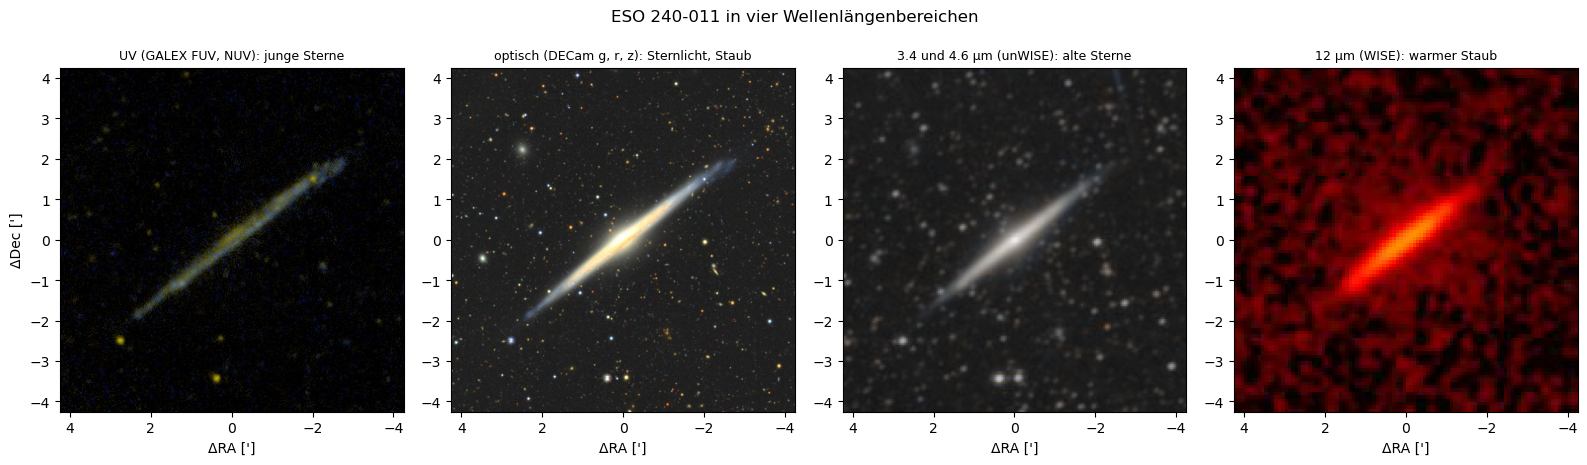

In [ ]:
# Farbbilder (JPEG) aus dem Legacy-Survey-Viewer, nur zur Ansicht; Ebene: (Titel, Pixelmaß ["/px])
EBENEN = {
    "galex":       ("UV (GALEX FUV, NUV): junge Sterne", 1.5),
    "ls-dr10":     ("optisch (DECam g, r, z): Sternlicht, Staub", None),
    "unwise-neo7": ("3.4 und 4.6 µm (unWISE): alte Sterne", 2.75),
    "wssa":        ("12 µm (WISE): warmer Staub", 5.0),
}

if DEMO:
    print("Im Demo-Modus gibt es keine Himmelsbilder.")
else:
    s = Simbad()
    s.add_votable_fields("galdim_majaxis")
    r = s.query_object(GALAXY)
    maj = np.nan if np.ma.is_masked(r["galdim_majaxis"][0]) else float(r["galdim_majaxis"][0])
    size_arcsec = 1.6 * 60 * (maj if np.isfinite(maj) else 3)       # Feld wie bei den FITS-Ausschnitten
    half = size_arcsec / 120                                         # halbe Feldbreite [']
    fig, axes = plt.subplots(1, len(EBENEN), figsize=(16, 4.4))
    for ax, (ebene, (titel, pix)) in zip(axes, EBENEN.items()):
        pix = pix or max(PIXSCALE, round(size_arcsec / NPIX_MAX, 3))
        fn = ASTRODATA / "decals" / f"{GALAXY.replace(' ', '_')}_{ebene}.jpg"
        if REFRESH or not fn.exists():
            url = (f"https://www.legacysurvey.org/viewer/jpeg-cutout?ra={float(r['ra'][0]):.6f}&dec={float(r['dec'][0]):.6f}"
                   f"&layer={ebene}&pixscale={pix}&size={int(size_arcsec / pix)}")
            try:
                urllib.request.urlretrieve(url, fn)
            except OSError:
                fn.unlink(missing_ok=True)
                ax.set_title(f"{titel}\n(nicht verfügbar)", fontsize=9)
                ax.axis("off")
                continue
        ax.imshow(plt.imread(fn), extent=[half, -half, -half, half])   # Zeilen des JPG laufen von Norden nach Süden
        ax.set_title(titel, fontsize=9)
        ax.set_xlabel("ΔRA [']")
    axes[0].set_ylabel("ΔDec [']")
    fig.suptitle(f"{GALAXY} in vier Wellenlängenbereichen", y=1.0)
    fig.tight_layout()
    plt.show()

##### *1. Bild und Katalogdaten laden*

Wo liegt die Galaxie, wie weit ist sie entfernt, und wie sieht sie im r-Band aus, bevor man etwas bearbeitet?

ESO 240-011: RA 354.4559, Dec -47.7273, z = 0.00951, große Achse 5.3'
D = 44.3 Mpc (Median aus 6 Messungen ohne Rotverschiebung; cz/H0 = 40.7 Mpc)
1 px = 0.638" = 137 pc, Bild 800 x 800 px


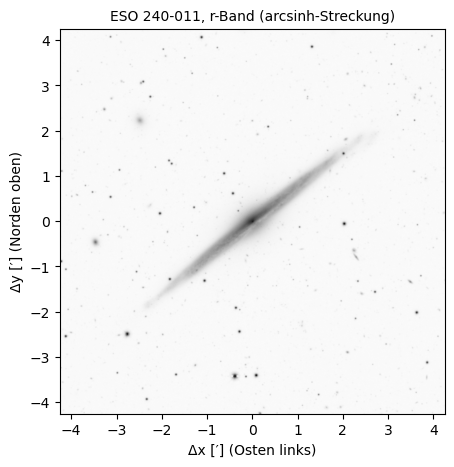

In [3]:
from functools import lru_cache

@lru_cache
def simbad_info(name):
    s = Simbad()
    s.add_votable_fields("rvz_redshift", "galdim_majaxis", "galdim_angle")
    r = s.query_object(name)
    g = lambda k: np.nan if np.ma.is_masked(r[k][0]) else float(r[k][0])
    info = dict(ra=g("ra"), dec=g("dec"), z=g("rvz_redshift"), maj_arcmin=g("galdim_majaxis"), pa_cat=g("galdim_angle"))
    # Entfernungen, die nicht aus der Rotverschiebung stammen (meist Tully-Fisher); Herleitung, Punkt 5
    d = Simbad.query_tap(f"""SELECT m.dist, m.unit, m.method FROM mesDistance AS m
                             JOIN basic AS b ON b.oid = m.oidref WHERE b.main_id = '{r["main_id"][0]}'""").to_pandas()
    d = d[d["method"].str.strip() != "redshift"]
    d_mpc = (d["dist"] * d["unit"].str.strip().map({"Mpc": 1.0, "kpc": 1e-3, "pc": 1e-6})).dropna()
    if len(d_mpc):
        info["D_Mpc"], info["D_quelle"] = d_mpc.median(), f"Median aus {len(d_mpc)} Messungen ohne Rotverschiebung"
    else:
        info["D_Mpc"], info["D_quelle"] = C_KMS * info["z"] / H0, "cz/H0"
    return info

def legacy_cutout(name, info, band="r"):
    size_arcsec = 1.6 * 60 * (info["maj_arcmin"] if np.isfinite(info["maj_arcmin"]) else 3)
    pix = max(PIXSCALE, round(size_arcsec / NPIX_MAX, 3))
    npix = int(size_arcsec / pix)
    fn = ASTRODATA / "decals" / f"{name.replace(' ', '_')}_{band}.fits"
    if REFRESH or not fn.exists():
        for layer in ("ls-dr10", "ls-dr9"):
            url = (f"https://www.legacysurvey.org/viewer/fits-cutout?ra={info['ra']:.6f}&dec={info['dec']:.6f}"
                   f"&layer={layer}&pixscale={pix}&size={npix}&bands={band}")
            try:
                urllib.request.urlretrieve(url, fn)
            except OSError:                         # außerhalb der Abdeckung antwortet der Server mit Fehler 500
                continue
            if np.nanmax(fits.getdata(fn)) > 0:     # nur Nullen: keine Abdeckung in dieser Ebene
                break
        else:
            fn.unlink(missing_ok=True)
            raise RuntimeError(f"keine Legacy-Survey-Daten im {band}-Band")
    hdu = fits.open(fn)[0]
    return np.nan_to_num(hdu.data.astype(float)), WCS(hdu.header)

def demo_galaxy(amp_O=6.0, amp_W=-6.0, pa=40.0, seed=1):
    # Exponentielle Scheibe mit sech²-Profil, Warp quadratisch ab R = 60 px (Amplituden in px)
    rng = np.random.default_rng(seed); n = 500; h, z0, Rw, Rm = 40.0, 4.0, 60.0, 160.0
    y, x = np.mgrid[:n, :n] - n / 2
    t = np.radians(pa - 90)                       # Bild: Norden oben, Osten links; R < 0 ist die Ostseite
    R = x * np.cos(t) + y * np.sin(t); Z = -x * np.sin(t) + y * np.cos(t)
    w = np.clip((np.abs(R) - Rw) / (Rm - Rw), 0, None) ** 2
    zc = np.where(R < 0, amp_O, amp_W) * w
    img = 200 * np.exp(-np.abs(R) / h) / np.cosh((Z - zc) / z0) ** 2
    for _ in range(25):                           # ein paar Sterne
        sx, sy = rng.uniform(-n/2, n/2, 2); img += rng.uniform(5, 200) * np.exp(-((x-sx)**2 + (y-sy)**2) / 4)
    img += rng.normal(0, 1.5, img.shape)
    w_ = WCS(naxis=2); w_.wcs.ctype = ["RA---TAN", "DEC--TAN"]; w_.wcs.crpix = [n/2+1, n/2+1]
    w_.wcs.crval = [150.0, -45.0]; w_.wcs.cdelt = [-PIXSCALE/3600, PIXSCALE/3600]
    info = dict(ra=150.0, dec=-45.0, z=0.01, maj_arcmin=n*PIXSCALE/60*0.8, pa_cat=pa,
                D_Mpc=C_KMS * 0.01 / H0, D_quelle="cz/H0")
    return img, w_, info

def load_galaxy(name, band="r"):
    if DEMO:
        img, wcs, info = demo_galaxy(**DEMO_CASES[name])
    else:
        info = dict(simbad_info(name))
        img, wcs = legacy_cutout(name, info, band)
    pix = proj_plane_pixel_scales(wcs)[0] * 3600                       # ["/px]
    info["kpc_per_px"] = info["D_Mpc"] * 1e3 * np.radians(pix / 3600)  # Herleitung, Punkt 5
    return img, wcs, pix, info

DEMO_CASES = {"demo_S": dict(amp_O=6, amp_W=-6), "demo_U": dict(amp_O=6, amp_W=6, pa=120),
              "demo_L": dict(amp_O=0, amp_W=7, pa=75), "demo_flach": dict(amp_O=0, amp_W=0, pa=10)}
if DEMO: GALAXY = "demo_S"

img, wcs, pix, info = load_galaxy(GALAXY)
print(f"{GALAXY}: RA {info['ra']:.4f}, Dec {info['dec']:+.4f}, z = {info['z']:.5f}, große Achse {info['maj_arcmin']:.1f}'")
d_hubble = "" if info["D_quelle"] == "cz/H0" else f"; cz/H0 = {C_KMS * info['z'] / H0:.1f} Mpc"
print(f"D = {info['D_Mpc']:.1f} Mpc ({info['D_quelle']}{d_hubble})")
print(f"1 px = {pix:.3f}\" = {info['kpc_per_px']*1e3:.0f} pc, Bild {img.shape[1]} x {img.shape[0]} px")

lo, hi = np.percentile(img, [5, 99.7])
ext = np.array([-1, 1, -1, 1]) * img.shape[0] * pix / 120         # Bogenminuten vom Bildzentrum
plt.figure(figsize=(5, 5))
plt.imshow(np.arcsinh((img - lo) / (hi - lo) * 10), origin="lower", cmap="gray_r", extent=ext)
plt.xlabel("Δx [′] (Osten links)"); plt.ylabel("Δy [′] (Norden oben)")
plt.title(f"{GALAXY}, r-Band (arcsinh-Streckung)", fontsize=10); plt.show()

#### **Reduktion**

##### *2. Himmel abziehen, Lage der Scheibe bestimmen, Bild drehen*

Unter welchem Winkel liegt die Scheibe im Bild, stimmt er mit dem Katalog überein, und wie weit reicht die Galaxie hinaus?

In [4]:
def reduce_image(img, wcs):
    _, med, std = sigma_clipped_stats(img, sigma=3)
    im = img - med
    # Zusammenhängende Quelle, die die Bildmitte enthält (= Galaxie, keine Sterne)
    sm = ndimage.gaussian_filter(im, 2)            # geglättet -> tiefere Isophote
    lab, _ = ndimage.label(ndimage.binary_opening(sm > 3 * sigma_clipped_stats(sm, sigma=3)[2], iterations=2))
    cy, cx = np.array(im.shape) // 2
    center = lab[cy-5:cy+6, cx-5:cx+6].ravel()
    m = lab == np.bincount(center[center > 0]).argmax()
    # Herleitung, Punkt 1: Schwerpunkt und zweite Momente der Helligkeit
    y, x = np.nonzero(m); f = im[m]
    xc, yc = np.average(x, weights=f), np.average(y, weights=f)
    mxx, myy = np.average((x-xc)**2, weights=f), np.average((y-yc)**2, weights=f)
    mxy = np.average((x-xc)*(y-yc), weights=f)
    theta = 0.5 * np.degrees(np.arctan2(2 * mxy, mxx - myy))   # Winkel der großen Achse gegen x
    # Positionswinkel am Himmel (Nord über Ost) über das WCS
    t = np.radians(theta)
    p1, p2 = wcs.pixel_to_world([xc, xc + 50*np.cos(t)], [yc, yc + 50*np.sin(t)])
    pa_t = p1.position_angle(p2).deg               # Himmelsrichtung, in die theta zeigt
    # ndimage.rotate legt die Richtung "angle" auf +x; das Ostende soll links liegen wie am Himmel
    angle = theta + 180 if pa_t < 180 else theta
    shift = (im.shape[0]/2 - yc, im.shape[1]/2 - xc)
    rot = ndimage.rotate(ndimage.shift(im, shift, order=1), angle, reshape=False, order=1)
    m_rot = ndimage.rotate(ndimage.shift(m.astype(float), shift, order=0), angle, reshape=False, order=0) > 0.5
    r_max = np.percentile(np.abs(np.nonzero(m_rot)[1] - im.shape[1]/2), 99)   # Ausdehnung der Isophote
    return rot, std, pa_t % 180, r_max

rot, bg_std, pa_own, r_max = reduce_image(img, wcs)
print(f"Himmelsrauschen: {bg_std:.3g} (Bildeinheiten)")
print(f"PA = {pa_own:.1f} Grad (Katalog: {info['pa_cat']:.0f} Grad)")
print(f"R_max (3-sigma-Isophote, geglättet) = {r_max:.0f} px = {r_max*info['kpc_per_px']:.1f} kpc")

Himmelsrauschen: 0.000862 (Bildeinheiten)
PA = 128.1 Grad (Katalog: 128 Grad)
R_max (3-sigma-Isophote, geglättet) = 311 px = 42.6 kpc


#### **Eigene Messung**

##### *3. Spine-Fit: Wo ist die Scheibe in jeder Spalte am hellsten?*

In wie vielen Spalten ist die Scheibe hell genug für einen Fit, und liegt die Spine auf einer Geraden?

207 Spalten gefittet, 170 behalten (SNR > 5.0, Ausreißer entfernt)


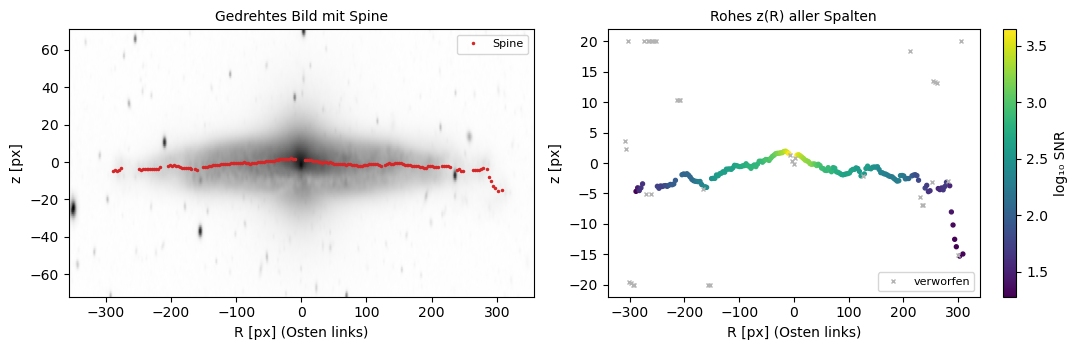

In [5]:
def gauss(z, A, z0, s, c): return A * np.exp(-0.5 * ((z - z0) / s) ** 2) + c

def fit_spine(rot, bg_std, r_max, zwin=None):
    ny, nx = rot.shape; cy, cx = ny // 2, nx // 2
    zwin = zwin or int(max(15, 0.25 * r_max))
    zz = np.arange(-zwin, zwin + 1)
    noise = bg_std / np.sqrt(BIN)                  # Herleitung, Punkt 2: Rauschen nach Mittelung über BIN Spalten
    rows = []
    for x0 in range(cx - int(r_max), cx + int(r_max) - BIN + 1, BIN):
        prof = rot[cy - zwin:cy + zwin + 1, x0:x0 + BIN].mean(axis=1)
        try:
            p, _ = curve_fit(gauss, zz, prof, p0=[prof.max(), zz[prof.argmax()], 3, 0], maxfev=2000)
        except RuntimeError:
            continue
        rows.append(dict(R=x0 + BIN/2 - cx, z=p[1], sig=abs(p[2]), snr=p[0] / noise))
    sp = pd.DataFrame(rows)
    ok = (sp.snr > SNR_MIN) & (sp.z.abs() < 0.8 * zwin) & sp.sig.between(0.5, zwin / 2)
    # Sterne sind schmaler als die Scheibe: Breite mit der inneren Scheibe vergleichen
    sig_disk = sp.sig[ok & (sp.R.abs() < R_INNER * r_max)].median()
    ok &= sp.sig > 0.6 * sig_disk
    # restliche Ausreißer gegen den gleitenden Median der behaltenen Punkte entfernen
    z_ok = sp.z[ok]
    d = z_ok - z_ok.rolling(7, center=True, min_periods=3).median()
    ok[d.index[d.abs() > 4 * 1.4826 * np.median(np.abs(d)) + 0.5]] = False
    return sp, ok

spine, ok = fit_spine(rot, bg_std, r_max)
print(f"{len(spine)} Spalten gefittet, {ok.sum()} behalten (SNR > {SNR_MIN}, Ausreißer entfernt)")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
lo, hi = np.percentile(rot, [5, 99.7]); cy, cx = np.array(rot.shape) // 2; w = int(1.15 * r_max)
ax[0].imshow(np.arcsinh((rot - lo) / (hi - lo) * 10)[cy - w//5:cy + w//5, cx - w:cx + w], origin="lower",
             cmap="gray_r", extent=[-w, w, -w//5, w//5], aspect="auto")
ax[0].plot(spine.R[ok], spine.z[ok], ".", ms=3, c="tab:red", label="Spine")
ax[0].set_title("Gedrehtes Bild mit Spine", fontsize=10)
ax[0].set_xlabel("R [px] (Osten links)"); ax[0].set_ylabel("z [px]"); ax[0].legend(fontsize=8)
sc = ax[1].scatter(spine.R[ok], spine.z[ok], c=np.log10(spine.snr[ok]), s=8, cmap="viridis")
ax[1].plot(spine.R[~ok], spine.z[~ok].clip(-20, 20), "x", c="0.7", ms=3, label="verworfen")
plt.colorbar(sc, ax=ax[1], label="log₁₀ SNR"); ax[1].legend(fontsize=8)
ax[1].set_title("Rohes z(R) aller Spalten", fontsize=10); ax[1].set_xlabel("R [px] (Osten links)"); ax[1].set_ylabel("z [px]")
plt.tight_layout(); plt.show()

#### **Modell und Fit**

##### *4. Referenzebene, Warp-Profil und Form*

Weicht die äußere Spine stärker von der inneren Ebene ab, als die Streuung der inneren Punkte erklären kann, und auf welcher Seite?

Innere Gerade: a = -0.0097 (Restdrehung -0.55 Grad), b = +0.06 px
Streuung innen s = 153 pc
Ostseite: z_warp = -842 pc (5.5 s) bei R = 32.9 kpc, Warp-Winkel -1.5 Grad
Westseite: z_warp = -255 pc (1.7 s) bei R = 37.7 kpc, Warp-Winkel -0.4 Grad
S-Anteil 294 pc, U-Anteil 549 pc  ->  L-Warp (einseitig), klar


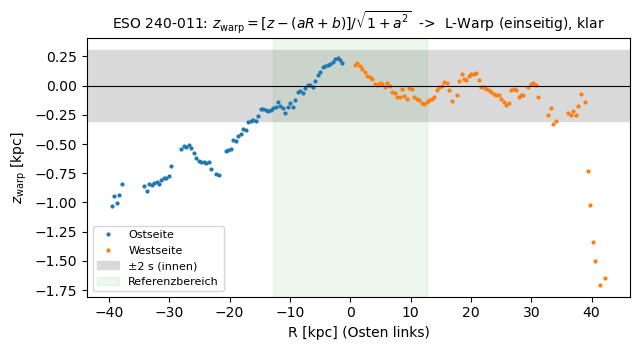

In [6]:
def warp_profile(spine, ok, r_max, kpc_per_px):
    s = spine[ok]
    inner = s.R.abs() < R_INNER * r_max
    a, b = np.polyfit(s.R[inner], s.z[inner], 1)                     # Herleitung, Punkt 3
    zw = (s.z - (a * s.R + b)) / np.sqrt(1 + a**2) * kpc_per_px      # Herleitung, Punkt 4
    Rk = s.R * kpc_per_px
    scat = 1.4826 * np.median(np.abs(zw[inner] - np.median(zw[inner])))
    scat = max(scat, 0.25 * kpc_per_px)            # Untergrenze: 1/4 Pixel (Systematik)
    res = dict(a=a, b=b, scatter_kpc=scat)
    for side, sel in (("O", s.R < 0), ("W", s.R > 0)):               # Osten links, Westen rechts
        outer = sel & (s.R.abs() > 0.75 * s.R[sel].abs().max())      # äußerstes Viertel dieser Seite
        enough = outer.sum() >= 3
        res[f"amp_{side}"] = np.median(zw[outer]) if enough else np.nan
        res[f"R_{side}"] = np.median(Rk[outer].abs()) if enough else np.nan
        res[f"sig_{side}"] = abs(res[f"amp_{side}"]) / scat
        res[f"psi_{side}"] = np.degrees(np.arctan2(res[f"amp_{side}"], res[f"R_{side}"]))   # Herleitung, Punkt 6
    res["S"] = (res["amp_W"] - res["amp_O"]) / 2   # Herleitung, Punkt 7: punktsymmetrischer Anteil
    res["U"] = (res["amp_W"] + res["amp_O"]) / 2   # spiegelsymmetrischer Anteil
    return Rk, zw, res

def classify(res):
    sO, sW = res["sig_O"] > 2, res["sig_W"] > 2
    if sO and sW:
        kind = "S-Warp" if np.sign(res["amp_O"]) != np.sign(res["amp_W"]) else "U-Warp"
    elif sO or sW:
        kind = "L-Warp (einseitig)"
    else:
        return "kein Warp"
    return kind + (", klar" if max(res["sig_O"], res["sig_W"]) > 4 else ", schwach")

Rk, zw, res = warp_profile(spine, ok, r_max, info["kpc_per_px"])
res["klasse"] = classify(res)
print(f"Innere Gerade: a = {res['a']:+.4f} (Restdrehung {np.degrees(np.arctan(res['a'])):+.2f} Grad), b = {res['b']:+.2f} px")
print(f"Streuung innen s = {res['scatter_kpc']*1e3:.0f} pc")
for side, label in (("O", "Ostseite"), ("W", "Westseite")):
    print(f"{label}: z_warp = {res['amp_' + side]*1e3:+.0f} pc ({res['sig_' + side]:.1f} s) bei R = {res['R_' + side]:.1f} kpc, "
          f"Warp-Winkel {res['psi_' + side]:+.1f} Grad")
print(f"S-Anteil {abs(res['S'])*1e3:.0f} pc, U-Anteil {abs(res['U'])*1e3:.0f} pc  ->  {res['klasse']}")

plt.figure(figsize=(6.5, 3.6))
for label, sel, c in (("Ostseite", Rk < 0, "tab:blue"), ("Westseite", Rk > 0, "tab:orange")):
    plt.plot(Rk[sel], zw[sel], ".", c=c, ms=4, label=label)
plt.axhline(0, c="k", lw=0.8)
plt.axhspan(-2 * res["scatter_kpc"], 2 * res["scatter_kpc"], color="0.85", label="±2 s (innen)")
r_in = R_INNER * r_max * info["kpc_per_px"]
plt.axvspan(-r_in, r_in, color="tab:green", alpha=0.08, label="Referenzbereich")
plt.xlabel("R [kpc] (Osten links)"); plt.ylabel(r"$z_\mathrm{warp}$ [kpc]")
plt.title(rf"{GALAXY}: $z_\mathrm{{warp}} = [z-(aR+b)]/\sqrt{{1+a^2}}$  ->  {res['klasse']}", fontsize=10)
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

##### *5. Staub oder Geometrie?*

Liegt die Spine im g-, r- und z-Band an derselben Stelle, oder verschiebt Staub sie je nach Wellenlänge (Herleitung, Punkt 8)?

g: Ost  -799 pc, West  -987 pc, s = 225 pc  ->  U-Warp, klar
r: Ost  -842 pc, West  -255 pc, s = 153 pc  ->  L-Warp (einseitig), klar


z: Ost  -842 pc, West    -3 pc, s = 113 pc  ->  L-Warp (einseitig), klar


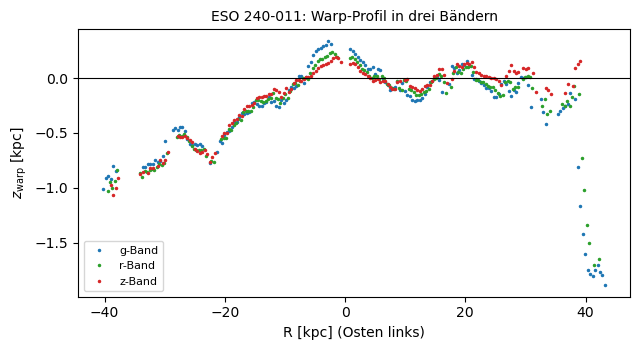

In [7]:
def warp_in_band(name, band):
    img_b, wcs_b, _, info_b = load_galaxy(name, band)
    rot_b, bg_b, _, rmax_b = reduce_image(img_b, wcs_b)
    sp_b, ok_b = fit_spine(rot_b, bg_b, rmax_b)
    return warp_profile(sp_b, ok_b, rmax_b, info_b["kpc_per_px"])

if DEMO:
    print("Die Demo-Galaxien haben nur ein Band; dieser Schritt braucht echte Daten.")
else:
    plt.figure(figsize=(6.5, 3.6))
    for band, c in (("g", "tab:blue"), ("r", "tab:green"), ("z", "tab:red")):
        Rk_b, zw_b, res_b = warp_in_band(GALAXY, band)
        plt.plot(Rk_b, zw_b, ".", c=c, ms=3, label=f"{band}-Band")
        print(f"{band}: Ost {res_b['amp_O']*1e3:+5.0f} pc, West {res_b['amp_W']*1e3:+5.0f} pc, "
              f"s = {res_b['scatter_kpc']*1e3:3.0f} pc  ->  {classify(res_b)}")
    plt.axhline(0, c="k", lw=0.8)
    plt.xlabel("R [kpc] (Osten links)"); plt.ylabel(r"$z_\mathrm{warp}$ [kpc]")
    plt.title(f"{GALAXY}: Warp-Profil in drei Bändern", fontsize=10)
    plt.legend(fontsize=8); plt.tight_layout(); plt.show()

#### **Eigene Messung gegen den Katalog**

##### *6. Stichprobe und Warp-Katalog*

Trifft der eigene Positionswinkel den Katalogwert, und findet die Methode die Warps, die Sánchez-Saavedra et al. (2003) auf DSS-Bildern gesehen haben? Die Stichprobe enthält zwei Galaxien, die dort als unverbogen gelten (ESO 240-011, IC 2531), drei mit S-Warp (IC 5176, IC 4351, IC 2000) und zwei nördlich des Katalogs mit bekannten HI-Warps: NGC 5907 (Sancisi 1976) und NGC 4013, dessen HI-Warp zu den stärksten bekannten gehört (Bottema, Shostak & van der Kruit 1987). Ist davon auch im Sternlicht etwas zu sehen?

In der Tabelle ist ψ der Warp-Winkel (Herleitung, Punkt 6), „Klasse (z)“ die Einordnung im z-Band (wie in Schritt 5) und „SS03“ Form und Winkel (Ost / West) aus dem Katalog. Im Demo-Modus vergleicht die Tabelle stattdessen die eingebaute Warp-Form mit der gefundenen.

In [8]:
SS03_URL = "https://cdsarc.cds.unistra.fr/ftp/J/A+A/399/457/"
SS03_TYP = {"N": "S", "S": "S", "LN": "L", "LS": "L", "U": "U", "-": "kein", "?": "unklar"}   # N, S: Drehsinn des S

def ss03_catalog():
    # Sánchez-Saavedra et al. (2003): Galaxien in Kantenlage südlich des Äquators, Warp-Winkel aus DSS-Bildern
    parts = []
    for t in ("table1.dat", "table2.dat"):                      # Spiralen, linsenförmige Galaxien
        fn = ASTRODATA / "vizier" / f"sanchez-saavedra2003_{t}"
        if REFRESH or not fn.exists():
            urllib.request.urlretrieve(SS03_URL + t, fn)
        parts.append(pd.read_fwf(fn, colspecs=[(6, 21), (22, 30), (31, 40), (56, 58), (59, 61), (63, 65)],
                                 names=["name", "ra_h", "dec", "typ", "psi_O", "psi_W"]))
    cat = pd.concat(parts, ignore_index=True)
    cat[["psi_O", "psi_W"]] = cat[["psi_O", "psi_W"]].apply(pd.to_numeric, errors="coerce")
    return cat

def ss03_entry(cat, ra, dec):
    sep = np.hypot((cat.ra_h * 15 - ra) * np.cos(np.radians(dec)), cat.dec - dec) * 60      # Bogenminuten
    if sep.min() > 1:
        return "–"
    e = cat.loc[sep.idxmin()]
    angles = "" if np.isnan(e.psi_O) else f", {e.psi_O:.0f}° / {e.psi_W:.0f}°"
    return SS03_TYP.get(str(e.typ).strip(), str(e.typ)) + angles

def analyse(name):
    img, wcs, pix, info = load_galaxy(name)
    rot, bg, pa, r_max = reduce_image(img, wcs)
    sp, ok = fit_spine(rot, bg, r_max)
    Rk, zw, res = warp_profile(sp, ok, r_max, info["kpc_per_px"])
    row = {"Galaxie": name, "D [Mpc]": round(info["D_Mpc"], 1),
           "PA eigen": round(pa, 1), "PA Katalog": info["pa_cat"], "R_max [kpc]": round(r_max * info["kpc_per_px"], 1),
           "Ost [pc]": round(res["amp_O"] * 1e3), "West [pc]": round(res["amp_W"] * 1e3),
           "s [pc]": round(res["scatter_kpc"] * 1e3),
           "ψ Ost/West [°]": f"{abs(res['psi_O']):.1f} / {abs(res['psi_W']):.1f}", "Klasse (r)": classify(res)}
    if not DEMO:
        try:
            row["Klasse (z)"] = classify(warp_in_band(name, "z")[2])
        except RuntimeError:                       # Lücken in der Abdeckung, z. B. IC 2531 ohne z-Band
            row["Klasse (z)"] = "kein z-Bild"
        row["SS03"] = ss03_entry(SS03, info["ra"], info["dec"])
    return row, (Rk, zw, res)

if DEMO:
    SAMPLE = list(DEMO_CASES)
else:
    SS03 = ss03_catalog()
    SAMPLE = ["ESO 240-011", "IC 2531", "IC 5176", "IC 4351", "IC 2000", "NGC 4013", "NGC 5907"]
rows, profiles = [], {}
for name in SAMPLE:
    try:
        row, profiles[name] = analyse(name)
        rows.append(row)
    except Exception as e:
        print(f"{name}: übersprungen ({e})")
tab = pd.DataFrame(rows).set_index("Galaxie")
if DEMO:
    tab.insert(0, "eingebaut", [f"O {DEMO_CASES[n].get('amp_O', 6):+g} / W {DEMO_CASES[n].get('amp_W', -6):+g} px" for n in tab.index])
tab

,D [Mpc],PA eigen,PA Katalog,R_max [kpc],Ost [pc],West [pc],s [pc],ψ Ost/West [°],Klasse (r),Klasse (z),SS03
Galaxie,,,,,,,,,,,
ESO 240-011,44.3,128.1,128.0,42.6,-842,-255,153,1.5 / 0.4,"L-Warp (einseitig), klar","L-Warp (einseitig), klar","kein, 0° / 0°"
IC 2531,35.6,74.3,74.0,42.2,-61,-82,62,0.1 / 0.2,kein Warp,kein z-Bild,"kein, 0° / 0°"
IC 5176,25.6,28.4,28.0,20.2,-548,534,80,1.9 / 1.8,"S-Warp, klar","S-Warp, klar","S, 3° / 3°"
IC 4351,31.1,19.9,18.0,31.8,681,-397,111,1.5 / 0.9,"S-Warp, klar","S-Warp, klar","S, 6° / 7°"
IC 2000,18.4,81.0,82.0,15.1,-76,377,108,0.4 / 1.8,"L-Warp (einseitig), schwach","L-Warp (einseitig), klar","S, 5° / 5°"
NGC 4013,17.9,64.9,64.0,15.3,-147,137,32,0.7 / 0.6,"S-Warp, klar","L-Warp (einseitig), schwach",–
NGC 5907,15.8,155.5,155.0,30.5,-43,-427,94,0.1 / 1.0,"L-Warp (einseitig), klar","U-Warp, klar",–


Wie sehen die Warp-Profile der Stichprobe nebeneinander aus, und woran erkennt man einen S-Warp, einen einseitigen Warp und eine ebene Scheibe?

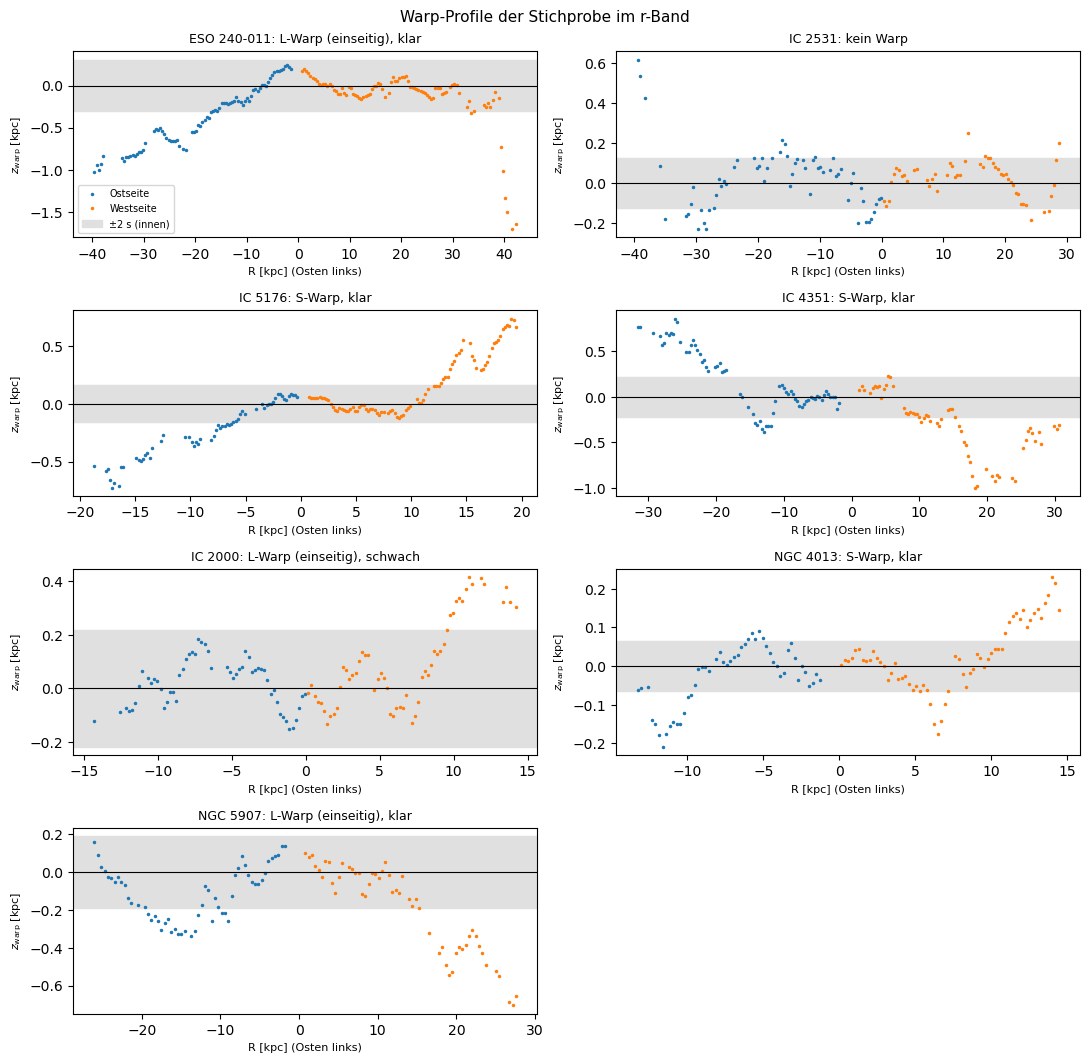

In [9]:
ncol = 2; nrow = int(np.ceil(len(profiles) / ncol))
fig, axs = plt.subplots(nrow, ncol, figsize=(11, 2.7 * nrow), squeeze=False)
for ax, (name, (Rk_g, zw_g, res_g)) in zip(axs.flat, profiles.items()):
    ax.plot(Rk_g[Rk_g < 0], zw_g[Rk_g < 0], ".", ms=3, c="tab:blue", label="Ostseite")
    ax.plot(Rk_g[Rk_g > 0], zw_g[Rk_g > 0], ".", ms=3, c="tab:orange", label="Westseite")
    ax.axhline(0, c="k", lw=0.8)
    ax.axhspan(-2 * res_g["scatter_kpc"], 2 * res_g["scatter_kpc"], color="0.88", label="±2 s (innen)")
    ax.set_title(f"{name}: {classify(res_g)}", fontsize=9)
    ax.set_xlabel("R [kpc] (Osten links)", fontsize=8); ax.set_ylabel(r"$z_\mathrm{warp}$ [kpc]", fontsize=8)
for ax in axs.flat[len(profiles):]:
    ax.axis("off")
axs[0, 0].legend(fontsize=7)
fig.suptitle("Warp-Profile der Stichprobe im r-Band", fontsize=11)
plt.tight_layout(); plt.show()

Ergebnis beim Lauf vom 2026-10-13 (ESO 240-011):

- **Antwort auf die Leitfrage:** Ja, aber schwach und nur auf einer Seite. Die Ostseite biegt ab etwa 10 kpc gleichmäßig nach unten ab und liegt im äußeren Viertel (Median bei R = 33 kpc) 0.84 kpc unter der Ebene der inneren Scheibe, das sind 5.5 s und ein Warp-Winkel von 1.5°. Die Westseite bleibt bis 37 kpc innerhalb von ±0.3 kpc eben. Formal ist das ein einseitiger Warp (L), klar.
- **Daten und Lage:** Der Median von sechs Entfernungen ohne Rotverschiebung (meist Tully-Fisher) ist 44.3 Mpc, cz/H0 gibt 40.7 Mpc; ein Pixel (0.638″) entspricht 137 pc. Der eigene Positionswinkel (128.1°) trifft den Katalogwert (128°), und die innere Gerade ist nur um −0.55° gegen die Bildachse gedreht. Die 3σ-Isophote reicht bis 42.6 kpc; 170 von 207 Spalten bleiben nach den Schnitten übrig.
- **Die Spine ist auch innen keine Gerade:** Sie hat in der Mitte eine flache Kuppel (bis +0.2 kpc über der Referenzgeraden) und fällt nach beiden Seiten ab. Deshalb ist die Streuung innen mit s = 153 pc größer als das Rauschen, und die Einordnung hängt am Referenzbereich: Mit `R_INNER = 0.5` wird aus dem einseitigen ein U-Warp (Variation 1). Fest steht nur: Die Ostseite ist um etwa 0.8 kpc nach unten verbogen, die Westseite bis kurz vor ihrem Ende nicht.
- **Die Westspitze:** Ab 38 kpc knickt ein schwacher Ausläufer um bis zu 1.7 kpc nach unten. Er ist im tiefen g- und r-Bild zu sehen und schließt glatt an die Scheibe an; im flacheren z-Bild fehlt er. Im Median des äußeren Viertels zählt er kaum (−0.26 kpc, 1.7 s). Weil er in dieselbe Richtung zeigt wie die Ostseite, ist der U-Anteil (0.55 kpc) größer als der S-Anteil (0.29 kpc).
- **Staub oder Geometrie:** Bis auf die Westspitze liegt die Spine in g, r und z an derselben Stelle; die Ostseite liegt in allen drei Bändern bei −0.80 bis −0.84 kpc. Die Verbiegung ist also geometrisch und kein Staubeffekt. Die unterschiedlichen Klassen (g: U, r und z: L) kommen allein von der Westspitze: Im g-Band reicht die Spine weiter hinaus, und der Ausläufer bestimmt dort den Median.
- **Katalog:** Alle sieben Positionswinkel stimmen auf 0.1° bis 1.9° mit SIMBAD überein. Die beiden Galaxien, die Sánchez-Saavedra et al. (2003) als unverbogen führen, sind es auch hier: IC 2531 hat keinen Warp (für sie gibt es in DR10 kein z-Bild), ESO 240-011 einen von 1.5°, weit unter den 4°, ab denen der Katalog einen Warp zählt. Bei den drei Katalog-S-Warps findet die Methode ebenfalls eine Verbiegung: IC 5176 und IC 4351 klar als S-Warp in r und z, IC 2000 nur auf der Westseite. Die eigenen Winkel sind durchweg kleiner, um einen Faktor 1.6 bis über 10 (IC 5176: 1.9°/1.8° gegen 3°/3°, IC 4351: 1.5°/0.9° gegen 6°/7°, IC 2000: 0.4°/1.8° gegen 5°/5°). Gründe: Der Katalog nimmt den äußersten sichtbaren Punkt, hier wird der Median des äußeren Viertels genommen; und der Katalog beurteilt die äußeren Isophoten auf DSS-Bildern von Auge, während hier die hellste Stelle jeder Spalte gemessen wird. Vergleichbar sind deshalb Form und Vorhandensein eines Warps, nicht die Zahl.
- **Die nördlichen HI-Warps:** NGC 4013 zeigt im r-Band einen kleinen S-Warp (−0.15 / +0.14 kpc, Winkel 0.7° / 0.6°), der im z-Band fast verschwindet (Variation 4): Was man hier im Sternlicht sieht, ist zum größten Teil ein Staubeffekt. Bei NGC 5907 biegt die Westseite ab etwa 15 kpc auf −0.4 bis −0.7 kpc ab, die Ostseite hat nur eine Delle bei −15 kpc; im z-Band wird daraus ein U-Warp. Der berühmte HI-Warp beginnt erst dort, wo die Sternscheibe endet (Sancisi 1976), also außerhalb dessen, was die Spine erreicht. Für beide Galaxien liegt die Entfernung aus Tully-Fisher (17.9 und 15.8 Mpc) weit über cz/H0 (11.9 und 9.5 Mpc).
- **Aussortiert:** ESO 362-11 und IC 4837A aus dem Katalog liegen neben hellen Sternen mit Ausblutungsstreifen. Dort werden Maske und Positionswinkel falsch (bei ESO 362-11 um 13°), deshalb fehlen sie in der Stichprobe.

#### **Variationen**

Jeweils zuerst die Vorhersage notieren, dann den Code ändern und prüfen:

1. **Referenzbereich:** `R_INNER = 0.15` bzw. `0.5`. *(Vorhersage: Bei ESO 240-011 entscheidet der Referenzbereich über die Form. Mit 0.15 geht die Gerade nur durch die Kuppel in der Mitte, beide Seiten liegen tiefer, die Ostseite bei −1.3 kpc, die Westseite bleibt eben: weiter einseitig. Mit 0.5 reicht der Bereich in die schon abbiegende Ostseite, die Gerade rutscht nach unten, und es wird ein U-Warp mit je −0.5 kpc.)*
2. **SNR-Schnitt:** `SNR_MIN = 3` bzw. `50`. *(Vorhersage: Mit 3 ändert sich nichts, denn die Spine endet schon an der Isophote aus Schritt 2, wo das SNR noch bei etwa 20 liegt. Mit 50 endet sie bei ±34 kpc, der Haken an der Westspitze fällt weg, und die Westseite wird flach; die Ostseite bleibt bei −0.8 kpc.)*
3. **Spaltenbreite:** `BIN = 1` bzw. `9`. *(Vorhersage: Die Ostseite bleibt bei −0.8 kpc. Die Streuung s ändert sich kaum, weil sie bei ESO 240-011 von der Kuppel in der Mitte bestimmt ist und nicht vom Rauschen.)*
4. **Ein Staubband:** `GALAXY = "NGC 4013"`, dann Schritt 5 ansehen. *(Vorhersage: Im g-Band ein S-Warp mit ±0.2 kpc, im z-Band bleibt fast nichts davon übrig. Die Verbiegung im Sternlicht kommt hier zum größten Teil vom Staub.)*
5. **Ein klarer S-Warp:** `GALAXY = "IC 4351"`. *(Vorhersage: S-Warp in allen drei Bändern, Ostseite oben, Westseite unten. Die Amplitude wächst von g nach z, auf der Ostseite von 0.4 auf 0.9 kpc: Staub täuscht hier keinen Warp vor, sondern dämpft ihn im blauen Licht.)*
6. **Nachweisgrenze:** `DEMO = True`, dann in `DEMO_CASES` die Amplituden von `demo_S` verkleinern. *(Vorhersage: ±1 px am Rand der eingebauten Scheibe wird noch als schwacher S-Warp gefunden, gemessen ±0.6 px; bei ±0.5 px nicht mehr. Die Grenze liegt bei 2 s, hier 2 · ¼ px.)*

#### **Nächste Schritte**

So würde eine Analyse in der Forschung weitergehen:
- **Sterne maskieren**, bevor die Spine gefittet wird (Positionen aus Gaia DR3), statt sie nur an ihrer Breite zu erkennen; helle Sterne mit Ausblutungsstreifen verderben sonst Maske und Positionswinkel.
- **Unsicherheiten pro Spalte** aus der Kovarianzmatrix von `curve_fit` übernehmen und Amplitude und Winkel gewichtet bestimmen, mit Fehlerbalken.
- **Ein Modell statt eines Medians:** $z_\mathrm{warp} = \alpha\,(|R|-R_w)^n$ für $|R| > R_w$ anpassen. Das liefert den Radius $R_w$, bei dem der Warp beginnt, und lässt sich mit dem Rand der Sternscheibe vergleichen.
- **Größere Stichprobe** aus Katalogen von Galaxien in Kantenlage, etwa EGIS (Bizyaev et al. 2014, aus SDSS) oder EGIPS (Makarov et al. 2022, aus Pan-STARRS): Häufigkeit und Form der Warps gegen Umgebung, Masse und Hubble-Typ.
- **Gas und Sterne vergleichen:** HI-Karten zeigen, ob der Sternwarp beim selben Radius beginnt und in dieselbe Richtung biegt wie der Gaswarp.
- **Kinematik:** Integralfeldspektren wie die von GECKOS zeigen, ob die verbogenen äußeren Bereiche anders rotieren als die innere Scheibe.

#### **Referenzen**

- Sancisi, R. (1976): *Warped HI disks in galaxies*, A&A 53, 159.
- Bottema, R., Shostak, G. S. & van der Kruit, P. C. (1987): *A prodigious warp in the HI disk of NGC 4013*, Nature 328, 401.
- Reshetnikov, V. & Combes, F. (1998): *Statistics of optical warps in spiral disks*, A&A 337, 9.
- García-Ruiz, I., Sancisi, R. & Kuijken, K. (2002): *Neutral hydrogen and optical observations of edge-on galaxies: Hunting for warps*, A&A 394, 769.
- Sánchez-Saavedra, M. L., Battaner, E., Guijarro, A., López-Corredoira, M. & Castro-Rodríguez, N. (2003): *A catalog of warps in spiral and lenticular galaxies in the Southern hemisphere*, A&A 399, 457.
- van der Kruit, P. C. & Searle, L. (1981): *Surface photometry of edge-on spiral galaxies. I. A model for the three-dimensional distribution of light in galactic disks*, A&A 95, 105.
- Sparke, L. S. & Casertano, S. (1988): *A model for persistent galactic warps*, MNRAS 234, 873.
- Ostriker, E. C. & Binney, J. J. (1989): *Warped and tilted galactic discs*, MNRAS 237, 785.
- Jiang, I.-G. & Binney, J. (1999): *Warps and cosmic infall*, MNRAS 303, L7.
- Weinberg, M. D. & Blitz, L. (2006): *A Magellanic origin for the warp of the Galaxy*, ApJ 641, L33.
- Chen, X. et al. (2019): *An intuitive 3D map of the Galactic warp's precession traced by classical Cepheids*, Nature Astronomy 3, 320.
- Schlafly, E. F. & Finkbeiner, D. P. (2011): *Measuring reddening with Sloan Digital Sky Survey stellar spectra and recalibrating SFD*, ApJ 737, 103.
- Dey, A. et al. (2019): *Overview of the DESI Legacy Imaging Surveys*, AJ 157, 168.
- van de Sande, J. et al. (2024): *GECKOS: Turning galaxy evolution on its side with deep observations of edge-on galaxies*, IAU Symposium 377, 27.
- Bizyaev, D. V. et al. (2014): *The catalog of edge-on disk galaxies from SDSS. I. The catalog and the structural parameters of stellar disks*, ApJ 787, 24.
- Makarov, D. I. et al. (2022): *The Edge-on Galaxies in the Pan-STARRS survey (EGIPS)*, MNRAS 511, 3063.